# 03b · Would a random split tell a different story?

**DSCI 510 project: Anticipating Attacks on Software Flaws** · companion to `03_model.ipynb`

`03_model.ipynb` judges every model the way a security team would use it: the model learns from
CVEs published in Nov 2021–2022 and is measured on CVEs published later, in 2023. A common
alternative shuffles all CVEs and splits them at random. This notebook asks whether that choice
matters: **would a random split have reported a different result for the same model?**

**How:** the final model chosen in `03_model.ipynb` (and, for reference, the publisher baseline) is
refitted under four designs, and **every design is measured on the same 2023 CVEs**, so any
difference comes from the design alone.

| Design | The model learns from | Size of the fitting data |
|:--|:--|:--|
| **Forward** (the design `03_model.ipynb` uses) | Nov 2021–2022 only | the training period |
| **Random, grouped, same size** | a random part of Nov 2021–2023, never from the CVE's own publisher-week | the same as forward |
| **Random, ungrouped, same size** | a random part of Nov 2021–2023 | the same as forward |
| **Random, ungrouped, all data** | the other four-fifths of Nov 2021–2023 | about 60% more |

Reading down the table, each step changes **one thing**, so each difference has one meaning:

| Comparison | What changes | What it measures |
|:--|:--|:--|
| forward → random, grouped | the model also learns from 2023-era CVEs | the cost of **drift**: how much a model loses by learning only from the past |
| grouped → ungrouped | related CVEs can fall on both sides | **leakage between related CVEs**: same publisher, same week, often one advisory or one campaign |
| same size → all data | about 60% more fitting data | the gain from **more data** |
| forward → random, ungrouped, all data | all of the above | what a **plain random split** would report instead of our result |

**Why it matters:** the descriptive analysis (`02_descriptive_analysis.ipynb`) found that publishing
practice drifts (fewer unscored CVEs each year, new publishers such as kernel.org in 2024) and that
exploited CVEs cluster by publisher. This notebook measures how much each of these matters for our
measure, coverage at a fixed effort.

| Stage | What happens |
|:--|:--|
| A · Setup | Settings (taken from `03_model.ipynb`'s frozen choices), records, and the evaluation tools, tested |
| B · Inputs | The data and the final model rebuilt exactly as in `03_model.ipynb`, and checked against its scores |
| C · The four designs | Random folds, out-of-fold scores, and checks that each design did what it claims |
| D · Results | Coverage of each design, the four steps between them, a chart, and what it means |
| E · Summary | Findings, checks and files |

**Inputs:** `data/processed/analysis_table.parquet`, and from `03_model.ipynb` (sealed copy): the frozen
choices `results/q2_selection.json`, the 2023 scores `data/processed/model_scores_validate.parquet` and
`results/q2_validation_models.csv`. Run `03_model.ipynb` first.

**Outputs:** `results/q2_split_check.csv`, `results/q2_split_check_differences.csv`,
`results/q2_split_check.json`, `results/q2_split_check_summary.json`, `figures/q2_split_check.png` and
`logs/split_check_log.json`.

**Runtime:** about 4 minutes on a fast machine and about 20 on the laptop used for this project
(`SPLIT_REPEATS = 1` in Step 2 makes it about three times quicker, but less stable).

**The test year is not touched:** only the CVEs of Nov 2021–2023 are used.

**The code:** the functions this notebook shares with `03_model.ipynb` (evaluation, cleaning, features,
model fitting) are copied from it word for word when the notebooks are built, and the test runner
checks that they still match. Step 8 also checks that the rebuilt final model gives exactly the 2023
scores `03_model.ipynb` saved.

---

## Stage A · Setup

### Step 1 · Libraries

**What we are doing:** importing the libraries and recording their versions.

In [1]:
import hashlib, json, re, sys, time
import datetime as dt
from pathlib import Path

import numpy as np
import pandas as pd
import scipy.sparse as sp
import sklearn
import matplotlib
import matplotlib.pyplot as plt
from matplotlib import font_manager
from matplotlib.ticker import PercentFormatter
from sklearn.decomposition import TruncatedSVD
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score
from sklearn.model_selection import StratifiedGroupKFold, StratifiedKFold
from sklearn.preprocessing import OneHotEncoder, StandardScaler

VERSIONS = {"python": sys.version.split()[0], "pandas": pd.__version__, "numpy": np.__version__,
            "scikit-learn": sklearn.__version__, "matplotlib": matplotlib.__version__}
print(" | ".join(f"{name} {version}" for name, version in VERSIONS.items()))

python 3.14.6 | pandas 3.0.3 | numpy 2.4.6 | scikit-learn 1.9.0 | matplotlib 3.11.0


**Reading the result:** one line of versions. Use the same computer and environment as for
`03_model.ipynb`, so the final model is fitted exactly as there.

### Step 2 · Settings

**What we are doing:** fixing the folders and this notebook's own two settings, and reading every
other setting from the choices `03_model.ipynb` froze in `results/q2_selection.json`: the final
model and its settings, the feature settings, the efforts and the random seed.

**Why:** taking the settings from the frozen file, instead of typing them again, guarantees that the
model compared here is exactly the one `03_model.ipynb` chose.

In [2]:
# ---- Folders and this notebook's settings ----
PROCESSED, RAW = Path("data") / "processed", Path("data") / "raw"
RESULTS, FIGURES, LOGS = Path("results"), Path("figures"), Path("logs")
for folder in (RESULTS, FIGURES, LOGS):
    folder.mkdir(parents=True, exist_ok=True)
LABEL = "label_365"                       # listed in KEV within 365 calendar days of publication
N_BOOT = 1000                             # bootstrap resamples, as in 03_model.ipynb
SPLIT_FOLDS, SPLIT_REPEATS = 5, 3         # 5 random parts; 3 random assignments, averaged (1: quicker, less stable)

# ---- The choices frozen by 03_model.ipynb ----
SELECTION_FILE = RESULTS / "q2_selection.json"
if not SELECTION_FILE.exists():
    raise FileNotFoundError("results/q2_selection.json not found: run 03_model.ipynb (the sealed copy) first")
SELECTION = json.loads(SELECTION_FILE.read_text(encoding="utf-8"))
_frozen = SELECTION["settings"]
SEED, EFFORTS, PRIMARY_EFFORT = _frozen["seed"], _frozen["efforts"], _frozen["primary_effort"]
MIN_CATEGORY, MAX_CATEGORIES = _frozen["min_category"], _frozen["max_categories"]
SVD_COMPONENTS = _frozen["svd_components"]
TFIDF = {**_frozen["tfidf"], "ngram_range": tuple(_frozen["tfidf"]["ngram_range"])}
FINAL = SELECTION["final_model"]
FINAL_MODEL = SELECTION["candidates"][FINAL]           # family, feature set and settings
PUBLISHER_PSEUDO = SELECTION["baselines"]["publisher_pseudo_cves"]
print(f"final model from 03_model.ipynb: {FINAL} {FINAL_MODEL['params']} | seed {SEED} | efforts {EFFORTS}")
print(f"{SPLIT_FOLDS} folds, {SPLIT_REPEATS} repeat(s)")

final model from 03_model.ipynb: LR · structured + text {'C': 0.1} | seed 510 | efforts [0.05, 0.1, 0.26]
5 folds, 3 repeat(s)


**Reading the result:** the final model and its settings as `03_model.ipynb` froze them (in the run
of 15 Nov 2026: `LR · structured + text` with `C = 0.1`), and this notebook's two settings. A
`FileNotFoundError` means `03_model.ipynb` has not been run yet.

### Step 3 · Recording checks and saving outputs

**What we are doing:** the same small tools as in `03_model.ipynb` (`check`, `show_conditions`,
`save_table`, `save_json`), writing this notebook's own run log, `logs/split_check_log.json`.

In [3]:
def now_iso():
    "Current local time with its UTC offset."
    return dt.datetime.now().astimezone().isoformat(timespec="seconds")

def check(name, ok, **details):
    "Record one check and print its verdict. ok=True is PASS, False is FAIL, None is WARN."
    verdict = "WARN" if ok is None else ("PASS" if ok else "FAIL")
    RUN["checks"][name] = {"verdict": verdict, **details}
    print(f"{verdict}  {name}" + (f"  |  {details}" if details else ""))

def show_conditions(conditions):
    "Print a {description: passed} checklist; return the descriptions that failed."
    for description, passed in conditions.items():
        print(f"  {'ok ' if passed else 'NO '} {description}")
    return [description for description, passed in conditions.items() if not passed]

def save_table(df, name, index=True):
    "Save a result table as results/<name>.csv and remember it for the summary."
    path = RESULTS / f"{name}.csv"
    df.to_csv(path, index=index)
    RUN["files"].append(str(path))
    return path

def save_json(obj, path):
    "Write obj as indented JSON and remember the file."
    Path(path).write_text(json.dumps(obj, indent=2, default=str), encoding="utf-8")
    RUN["files"].append(str(path))

RUN = {"started": now_iso(), "checks": {}, "files": [], "versions": VERSIONS,
       "selection_sha256": SELECTION.get("sha256")}
LOG_FILE = LOGS / "split_check_log.json"                  # this notebook's own run log

**The chart style:** the same as in the other notebooks. Aqua marks the final model, grey the
publisher baseline.

In [4]:
SURFACE, GRID, AXIS = "#fcfcfb", "#e1e0d9", "#c3c2b7"
INK, INK_2, INK_3 = "#0b0b0b", "#52514e", "#898781"           # primary, secondary, muted text
SET_COLORS = {"structured": "#2a78d6", "text": "#eb6834", "structured + text": "#1baf7a"}
BASELINE_GREY = "#898781"

def pick_font(candidates=("Segoe UI", "Helvetica Neue", "Arial", "DejaVu Sans")):
    "The first installed font from the list (checked quietly, so matplotlib prints no warnings)."
    for name in candidates:
        try:
            font_manager.findfont(name, fallback_to_default=False)
            return name
        except ValueError:
            continue
    return "sans-serif"

plt.rcParams.update({
    "font.family": pick_font(), "font.size": 9.5,
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": AXIS, "axes.linewidth": 0.8, "axes.labelcolor": INK_2,
    "axes.titlesize": 11.5, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.titlecolor": INK, "axes.spines.top": False, "axes.spines.right": False,
    "xtick.color": INK_3, "ytick.color": INK_3, "xtick.labelcolor": INK_2, "ytick.labelcolor": INK_2,
    "grid.color": GRID, "grid.linewidth": 0.8, "legend.frameon": False, "text.color": INK,
})

def save_figure(fig, name, note=None):
    "Add an optional note just below everything drawn, save figures/<name>.png, and show the figure."
    if note:
        fig.canvas.draw()                                         # lay out first, so the bounding box is final
        box = fig.get_tightbbox(fig.canvas.get_renderer())       # in inches
        fig.text(box.x0 / fig.get_figwidth(), (box.y0 - 0.08) / fig.get_figheight(), note,
                 ha="left", va="top", fontsize=8, color=INK_3)
    path = FIGURES / f"{name}.png"
    fig.savefig(path, dpi=200, bbox_inches="tight")
    RUN["files"].append(str(path))
    plt.show()
    plt.close(fig)

print("chart style ready | font:", pick_font())

chart style ready | font: Segoe UI


**Reading the result:** the font in use (Segoe UI on Windows; any fallback is fine).

### Step 4 · The evaluation tools

**What we are doing:** the measure of `03_model.ipynb`, copied unchanged: the expected **coverage**
(share of exploited CVEs caught) when a team handles the top share of CVEs (the **effort**), with
ties split evenly. `Ranking` sorts once; `coverage` measures at any effort.

In [5]:
class Ranking:
    "CVEs sorted by score, highest first, with equal scores grouped. Computed once per model, reused."
    def __init__(self, score):
        score = np.asarray(score, dtype=float)
        if score.size == 0 or not np.isfinite(score).all():
            raise ValueError("scores must be finite and not empty")
        self.order = np.argsort(-score, kind="stable")
        ranked = score[self.order]
        self.group = np.cumsum(np.r_[True, ranked[1:] != ranked[:-1]]) - 1   # tie-group number, in rank order
        self.n_groups, self.n = int(self.group[-1]) + 1, score.size

def coverage(ranking, y, efforts, weights=None):
    "Expected (coverage, precision) when the top `effort` share is handled, ties split evenly."
    y = np.asarray(y, dtype=float)[ranking.order]
    w = np.ones(ranking.n) if weights is None else np.asarray(weights, dtype=float)[ranking.order]
    size = np.bincount(ranking.group, weights=w, minlength=ranking.n_groups)       # CVEs per tie group
    hits = np.bincount(ranking.group, weights=w * y, minlength=ranking.n_groups)   # exploited per group
    cum_size, cum_hits = np.cumsum(size), np.cumsum(hits)
    k = np.asarray(efforts, dtype=float) * cum_size[-1]                           # CVEs handled
    g = np.minimum(np.searchsorted(cum_size, k, side="left"), ranking.n_groups - 1)  # group holding the cut
    taken = np.divide(k - (cum_size[g] - size[g]), size[g], out=np.zeros_like(k), where=size[g] > 0)
    found = cum_hits[g] - hits[g] + hits[g] * np.clip(taken, 0, 1)
    total = cum_hits[-1]
    cov = found / total if total > 0 else np.full_like(k, np.nan)
    return cov, np.divide(found, k, out=np.full_like(k, np.nan), where=k > 0)

The cell above defines the measure. The next one adds its uncertainty: a **paired bootstrap**, in
which every ranking is measured on the same 1,000 resamples of CVEs, so the interval for a
*difference* between two rankings is fair. `difference` gives that interval.

In [6]:
def bootstrap_coverage(y, rankings, efforts, n_boot=N_BOOT, seed=SEED):
    "Coverage of every ranking on the same resamples of CVEs: an array (n_boot, rankings, efforts)."
    rng, n = np.random.default_rng(seed), len(y)
    out = np.empty((n_boot, len(rankings), len(efforts)))
    for b in range(n_boot):
        weights = np.bincount(rng.integers(0, n, n), minlength=n)    # how often each CVE was drawn
        for j, ranking in enumerate(rankings.values()):
            out[b, j] = coverage(ranking, y, efforts, weights)[0]
    return out

def tag(effort):
    "Column suffix for an effort: 0.10 -> '10'."
    return f"{round(effort * 100)}"

def evaluation_table(y, scores, efforts=EFFORTS, n_boot=N_BOOT):
    "Coverage (with 95% interval) and precision at each effort, and average precision, per model."
    rankings = {name: Ranking(s) for name, s in scores.items()}
    boot = bootstrap_coverage(y, rankings, efforts, n_boot)
    rows = []
    for j, (name, ranking) in enumerate(rankings.items()):
        cov, prec = coverage(ranking, y, efforts)
        row = {"model": name}
        for i, e in enumerate(efforts):
            low, high = np.percentile(boot[:, j, i], [2.5, 97.5])
            row.update({f"coverage_{tag(e)}": cov[i], f"coverage_{tag(e)}_low": low,
                        f"coverage_{tag(e)}_high": high, f"precision_{tag(e)}": prec[i]})
        row["average_precision"] = average_precision_score(y, scores[name])
        rows.append(row)
    return pd.DataFrame(rows).set_index("model"), boot

def difference(table, boot, a, b, effort):
    "Coverage of model b minus model a at one effort, with its paired 95% interval."
    names, i = list(table.index), EFFORTS.index(effort)
    diffs = boot[:, names.index(b), i] - boot[:, names.index(a), i]
    estimate = table.loc[b, f"coverage_{tag(effort)}"] - table.loc[a, f"coverage_{tag(effort)}"]
    return (estimate, *np.percentile(diffs, [2.5, 97.5]))

**Testing the tools:** a perfect ranking, a fully tied one, and two identical rankings, whose
answers are known.

In [7]:
y10 = np.array([1, 1, 0, 0, 0, 0, 0, 0, 0, 0])
perfect = coverage(Ranking(np.arange(10, 0, -1)), y10, [0.2])[0][0]
tied = coverage(Ranking(np.zeros(10)), y10, [0.3])[0][0]
same = bootstrap_coverage(y10, {"a": Ranking(np.arange(10.0)), "b": Ranking(np.arange(10.0))}, EFFORTS, n_boot=50)
failed = show_conditions({
    "a perfect ranking catches both exploited CVEs at 20% effort": np.isclose(perfect, 1.0),
    "all scores tied: coverage 30% at 30% effort": np.isclose(tied, 0.3),
    "identical rankings differ by exactly zero on every resample":       # NaN where a resample has no exploited CVE
        np.array_equal(same[:, 0], same[:, 1], equal_nan=True),
})
check("S0-evaluation-selftest", not failed, tests=3, failed=failed)

  ok  a perfect ranking catches both exploited CVEs at 20% effort
  ok  all scores tied: coverage 30% at 30% effort
  ok  identical rankings differ by exactly zero on every resample
PASS  S0-evaluation-selftest  |  {'tests': 3, 'failed': []}


**Reading the result:** three `ok` lines and `PASS`.

---

## Stage B · Inputs

### Step 5 · The data and the outputs of `03_model.ipynb`

**What we are doing:** loading the analysis table (the CVEs of Nov 2021–2023 only), the 2023 scores
that `03_model.ipynb` saved, and its 2023 results, and checking that they belong together.

**Why:** the forward design's scores are the ones `03_model.ipynb` produced, so its result is
reproduced exactly. The frozen choices are checked against their fingerprint, so an edited file
cannot slip through.

In [8]:
table = pd.read_parquet(PROCESSED / "analysis_table.parquet")
keep = ["cve_id", "published", "cna", "description", "cvss_score", "cvss_vector", "cvss_version", "cwe_primary",
        LABEL, "kev_before_publication"]
frames = {p: table.loc[table["split"] == p, keep].reset_index(drop=True) for p in ("train", "validate")}
y_train, y_val = (frames[p][LABEL].to_numpy(int) for p in ("train", "validate"))
scores_03 = pd.read_parquet(PROCESSED / "model_scores_validate.parquet")
models_03 = pd.read_csv(RESULTS / "q2_validation_models.csv", index_col=0)

content = {k: v for k, v in SELECTION.items() if k not in ("sha256", "frozen_at")}
failed = show_conditions({
    "the frozen choices match their fingerprint":
        hashlib.sha256(json.dumps(content, sort_keys=True, default=str).encode("utf-8")).hexdigest()
        == SELECTION.get("sha256"),
    "the saved 2023 scores are aligned with the 2023 CVEs": scores_03["cve_id"].equals(frames["validate"]["cve_id"]),
    "the final model and the publisher baseline have saved scores":
        {FINAL, "Publisher's past rate"} <= set(scores_03.columns),
    "only the training and validation periods are loaded": sum(len(f) for f in frames.values())
        == int(table["split"].isin(["train", "validate"]).sum()),
})
for p, f in frames.items():
    print(f"{p:>8}: {len(f):,} CVEs, {int(f[LABEL].sum())} exploited")
check("S1-inputs-from-03", not failed, selection_sha256=SELECTION.get("sha256"), failed=failed)

  ok  the frozen choices match their fingerprint
  ok  the saved 2023 scores are aligned with the 2023 CVEs
  ok  the final model and the publisher baseline have saved scores
  ok  only the training and validation periods are loaded
   train: 28,368 CVEs, 128 exploited
validate: 28,816 CVEs, 145 exploited
PASS  S1-inputs-from-03  |  {'selection_sha256': '86f7a97f7255a4465e881882e555faf5bcf1dba63651c53ee7fa518468716703', 'failed': []}


**Reading the result:** four `ok` lines and `PASS`, and the two periods: 28,368 CVEs (128 exploited)
and 28,816 (145 exploited). A `FAIL` on the fingerprint means `results/q2_selection.json` was edited
or comes from another run; run `03_model.ipynb` again.

### Step 6 · Publisher names and the cleaned descriptions

**What we are doing:** the publisher names and the cleaning of `03_model.ipynb` (Steps 7 and 9),
copied unchanged: every sentence that says a flaw is or was exploited is removed from the description.

In [9]:
try:
    _sources = json.loads((RAW / "nvd_sources.json").read_text(encoding="utf-8"))
except (FileNotFoundError, json.JSONDecodeError):
    _sources = []
PUBLISHER_NAMES = {identifier: s["name"].strip() for s in _sources if s.get("name")
                   for identifier in s.get("sourceIdentifiers", [])}

def publisher_of(df):
    "The publisher's name where known, otherwise its identifier."
    return df["cna"].map(PUBLISHER_NAMES).fillna(df["cna"])

print(f"publisher names: {len(PUBLISHER_NAMES):,} identifiers")

publisher names: 831 identifiers


**The cleaning:** the phrases that state exploitation, and the function that drops every sentence
containing one, both unchanged from `03_model.ipynb`.

In [10]:
EXPLOITATION_PHRASES = [
    r"\bexploited in the wild\b", r"\bin the wild\b", r"\bactively exploited\b",
    r"\b(?:has|have|had|may have) been (?:actively )?exploited\b", r"\b(?:was|were) (?:actively )?exploited\b",
    r"\bis being (?:actively )?exploited\b", r"\btargeted exploitation\b",
    r"\bexploitation (?:has been |was )?(?:observed|detected|reported)\b",
    r"\bknown exploited vulnerabilit", r"\baware of (?:a |an )?(?:report|reports|exploit)",
]

PHRASE = re.compile("|".join(EXPLOITATION_PHRASES), re.IGNORECASE)

def has_phrase(texts):
    "True where a text states that the flaw is or was exploited."
    return texts.fillna("").str.contains(PHRASE)

SENTENCE_END = re.compile(r"(?<=[.!?])\s+")

def mask_exploitation(text):
    "The description without any sentence that says the flaw is or was exploited."
    if not isinstance(text, str):
        return ""
    if not PHRASE.search(text):
        return text                                    # untouched, spacing included
    return " ".join(s for s in SENTENCE_END.split(text) if not PHRASE.search(s))

for f in frames.values():
    f["text"] = f["description"].map(mask_exploitation)                 # what the models read
changed = sum(int((f["text"] != f["description"].fillna("")).sum()) for f in frames.values())
print(f"descriptions changed by the cleaning: {changed}")

descriptions changed by the cleaning: 148


**Reading the result:** the number of named identifiers (831 with the cache of `02`) and the number of
descriptions the cleaning changed (148, as in `03_model.ipynb`).

### Step 7 · The model's inputs

**What we are doing:** the features of `03_model.ipynb` (Steps 11–13), copied unchanged: the parts of
the CVSS vector, the structured inputs, and their encoder.

In [11]:
COMPONENTS = ["AV", "AC", "PR", "UI", "S", "AT", "C", "I", "A"]

V4_NAMES = {"VC": "C", "VI": "I", "VA": "A"}

def vector_components(vectors):
    "One column per CVSS 3.x/4.0 base component (codes such as N, L, H); 'missing' where absent."
    modern = vectors.where(vectors.str.startswith("CVSS:3", na=False) | vectors.str.startswith("CVSS:4", na=False))
    pairs = modern.str.findall(r"/([A-Z]+):([A-Z])")
    rows = [{V4_NAMES.get(k, k): v for k, v in p} if isinstance(p, list) else {} for p in pairs]
    parsed = pd.DataFrame(rows, index=vectors.index).reindex(columns=COMPONENTS)
    parsed["UI"] = parsed["UI"].replace({"P": "R", "A": "R"})   # passive or active: required either way
    return parsed.fillna("missing")

CATEGORICAL = ["publisher", "cwe", "cvss_version"] + COMPONENTS

NUMERIC = ["cvss_score", "log_description_len"]

def structured_inputs(df):
    "The structured inputs of each CVE, as readable columns (categories as text, two numbers)."
    raw = pd.DataFrame({"publisher": publisher_of(df), "cwe": df["cwe_primary"].fillna("missing"),
                        "cvss_version": df["cvss_version"].fillna("missing").astype(str)}, index=df.index)
    raw = raw.join(vector_components(df["cvss_vector"]))
    raw["cvss_score"] = df["cvss_score"].astype(float).fillna(0.0)
    raw["log_description_len"] = np.log1p(df["text"].str.len().astype(float))
    return raw

The cell above turns each CVE into readable inputs. The next one encodes them, learning which
publishers and CWEs get their own column from the fitting data only.

In [12]:
class StructuredEncoder:
    "Keeps the categories common in the fitting data (the rest become 'other'); encodes for both model families."
    def fit(self, raw):
        self.keep, self.n_fit = {}, len(raw)
        for col in CATEGORICAL:
            counts = raw[col].value_counts()
            common = counts[counts >= MIN_CATEGORY].index[:MAX_CATEGORIES - 1]
            self.keep[col] = sorted(set(common) | {"other"})
        lumped = self.lump(raw)
        self.onehot = OneHotEncoder(categories=[self.keep[c] for c in CATEGORICAL], handle_unknown="ignore",
                                    sparse_output=True).fit(lumped[CATEGORICAL])
        self.scaler = StandardScaler().fit(raw[NUMERIC])
        return self

    def lump(self, raw):
        "Categories not kept at fitting time (rare, or never seen) become 'other'."
        out = raw.copy()
        for col in CATEGORICAL:
            out[col] = out[col].where(out[col].isin(self.keep[col]), "other")
        return out

    def sparse(self, raw):
        "0/1 columns for each kept category, plus the standardised numbers (logistic regression)."
        lumped = self.lump(raw)
        return sp.hstack([self.onehot.transform(lumped[CATEGORICAL]),
                          sp.csr_matrix(self.scaler.transform(raw[NUMERIC]))]).tocsr()

    def dense(self, raw):
        "Category codes plus the raw numbers (gradient boosting)."
        lumped = self.lump(raw)
        codes = [pd.Categorical(lumped[c], categories=self.keep[c]).codes for c in CATEGORICAL]
        return np.column_stack(codes + [raw[c].to_numpy(float) for c in NUMERIC])

    def names(self):
        "Column names of the sparse form, in order (the one-hot columns follow self.keep)."
        return [f"{col}: {cat}" for col in CATEGORICAL for cat in self.keep[col]] + NUMERIC

The cell above handles the structured fields. The next one holds the text encoder and the way the
blocks are combined, both unchanged from `03_model.ipynb`.

In [13]:
class TextEncoder:
    "TF-IDF of the cleaned descriptions, learned from the fitting data, plus a dense SVD summary."
    def fit(self, texts):
        self.n_fit = len(texts)
        self.tfidf = TfidfVectorizer(dtype=np.float32, **TFIDF).fit(texts)
        tfidf = self.tfidf.transform(texts)
        n_components = min(SVD_COMPONENTS, tfidf.shape[1] - 1)
        self.svd = TruncatedSVD(n_components=n_components, random_state=SEED).fit(tfidf)
        return self

    def sparse(self, texts):
        return self.tfidf.transform(texts)

    def dense(self, texts):
        return self.svd.transform(self.tfidf.transform(texts))

    def names(self):
        return [f"word: {w}" for w in self.tfidf.get_feature_names_out()]

**Putting the blocks together:** `build_features` fits both encoders on one set of rows and encodes
others with them; `design` picks the blocks a model needs.

In [14]:
FEATURE_SETS = {"structured": ["structured"], "text": ["text"], "structured + text": ["structured", "text"]}

def build_features(fit_df, frames_to_encode, text_column="text"):
    "Fit both encoders on fit_df only, then encode every frame for both model families."
    s_enc = StructuredEncoder().fit(structured_inputs(fit_df))
    t_enc = TextEncoder().fit(fit_df[text_column])
    encoded = {}
    for name, df in frames_to_encode.items():
        raw = structured_inputs(df)
        encoded[name] = {"lr": {"structured": s_enc.sparse(raw), "text": t_enc.sparse(df[text_column])},
                         "gbm": {"structured": s_enc.dense(raw), "text": t_enc.dense(df[text_column])}}
    return s_enc, t_enc, encoded

def design(parts, family, feature_set):
    "The input matrix of one model family and feature set, and (for boosting) which columns are categories."
    blocks = [parts[family][b] for b in FEATURE_SETS[feature_set]]
    if family == "lr":
        return sp.hstack(blocks).tocsr(), None
    categorical = np.zeros(sum(b.shape[1] for b in blocks), dtype=bool)
    if "structured" in FEATURE_SETS[feature_set]:
        categorical[:len(CATEGORICAL)] = True                     # the structured block comes first
    return np.column_stack(blocks), categorical

### Step 8 · Fitting the final model, and checking it against `03_model.ipynb`

**What we are doing:** the fitting functions and the publisher baseline of `03_model.ipynb`, copied
unchanged, plus `fold_inputs`, which encodes one fit set and one scored set. For logistic regression
it skips the text summary (SVD) that only gradient boosting uses; that changes nothing in the scores,
only the time.

**Why the check:** the final model is refitted here on the training period and must give **exactly**
the 2023 scores `03_model.ipynb` saved. If it does, every design below uses the same model.

In [15]:
def fit_model(family, params, X, y, categorical=None):
    "Fit one model of the given family and settings; return the fitted model."
    if family == "logistic regression":
        model = LogisticRegression(C=params["C"], class_weight="balanced", solver="liblinear", max_iter=2000)
    else:
        model = HistGradientBoostingClassifier(
            learning_rate=0.05, max_iter=params["max_iter"], max_leaf_nodes=params["max_leaf_nodes"],
            min_samples_leaf=params["min_samples_leaf"], l2_regularization=1.0,
            categorical_features=categorical, early_stopping=False, random_state=SEED)
    return model.fit(X, y)

def predict(model, X):
    "Estimated probability of exploitation for each row."
    return model.predict_proba(X)[:, 1]

def publisher_baseline(fit_df, df, pseudo=50):
    "Each publisher's exploitation rate in fit_df, shrunk towards the overall rate; unseen ones get the overall rate."
    overall = fit_df[LABEL].mean()
    counts = fit_df[LABEL].groupby(publisher_of(fit_df)).agg(["sum", "size"])
    rate = (counts["sum"] + pseudo * overall) / (counts["size"] + pseudo)
    return publisher_of(df).map(rate).fillna(overall).to_numpy(float)

**One fit set, one scored set:** `fold_inputs` encodes them (encoders learned from the fit set only),
and `fit_and_score` fits the final model with its frozen settings and scores the other set.

In [16]:
FAMILY_SHORT = {"logistic regression": "lr", "gradient boosting": "gbm"}

def fold_inputs(fit_df, out_df, family):
    "Inputs of the final model for a fit set and a scored set, with encoders fitted on the fit set only."
    if FAMILY_SHORT[family] == "gbm":
        _, _, enc = build_features(fit_df, {"fit": fit_df, "out": out_df})
        return enc["fit"], enc["out"]
    s_enc = StructuredEncoder().fit(structured_inputs(fit_df))
    words = TfidfVectorizer(dtype=np.float32, **TFIDF).fit(fit_df["text"])     # as TextEncoder, without the SVD
    encode = lambda df: {"lr": {"structured": s_enc.sparse(structured_inputs(df)), "text": words.transform(df["text"])}}
    return encode(fit_df), encode(out_df)

def fit_and_score(fit_df, out_df):
    "Fit the final model (frozen settings) on fit_df and score out_df."
    fam = FAMILY_SHORT[FINAL_MODEL["family"]]
    fit_parts, out_parts = fold_inputs(fit_df, out_df, FINAL_MODEL["family"])
    X_fit, categorical = design(fit_parts, fam, FINAL_MODEL["feature_set"])
    model = fit_model(FINAL_MODEL["family"], FINAL_MODEL["params"], X_fit, fit_df[LABEL].to_numpy(int), categorical)
    return predict(model, design(out_parts, fam, FINAL_MODEL["feature_set"])[0])

**The check:** the next cell refits the final model on the training period, scores 2023, and compares
the scores with those `03_model.ipynb` saved; the publisher baseline likewise.

In [17]:
t0 = time.perf_counter()
refit = fit_and_score(frames["train"], frames["validate"])
publisher_refit = publisher_baseline(frames["train"], frames["validate"], PUBLISHER_PSEUDO)
failed = show_conditions({
    "the refitted final model gives 03's 2023 scores": np.allclose(refit, scores_03[FINAL], rtol=0, atol=1e-9),
    "the publisher baseline gives 03's 2023 scores":
        np.allclose(publisher_refit, scores_03["Publisher's past rate"], rtol=0, atol=1e-12),
})
print(f"refitted in {time.perf_counter() - t0:.0f} s")
check("S2-model-reproduced", not failed, final_model=FINAL, failed=failed)

  ok  the refitted final model gives 03's 2023 scores
  ok  the publisher baseline gives 03's 2023 scores
refitted in 18 s
PASS  S2-model-reproduced  |  {'final_model': 'LR · structured + text', 'failed': []}


**Reading the result:** two `ok` lines and `PASS`. A `FAIL` means this notebook is not fitting the
same model as `03_model.ipynb` (for example, a different library version since its run), and the
comparison below would not be fair.

---

## Stage C · The four designs

### Step 9 · The CVEs of Nov 2021–2023, and how they cluster

**How the random designs work:**

- **Folds.** The CVEs of Nov 2021–2023 are split at random into 5 parts (`SPLIT_FOLDS`). Each part is
  scored by a model fitted on the other four, with encoders, vocabulary and publisher rates learned
  from those four only. Only the scores of the 2023 CVEs are then measured.
- **Grouping.** A *publisher-week* is all CVEs from one publisher in one calendar week (Monday to
  Sunday). The grouped design keeps each publisher-week inside one part (scikit-learn's
  `StratifiedGroupKFold`); the ungrouped design ignores it (`StratifiedKFold`). Both spread the
  exploited CVEs evenly over the parts.
- **Same size.** From the other four parts, a random subset is drawn with exactly as many CVEs, and as
  many exploited CVEs, as the training period, so the comparison with forward is not about size.
- **Repeats.** The random parts depend on luck, so everything is repeated `SPLIT_REPEATS` times with
  different seeds, and the coverages are averaged.
- **Intervals.** Paired bootstrap over the 2023 CVEs: every repeat is measured on the same 1,000
  resamples, and the resamples are averaged over the repeats.

**The data for the check:** the next cell gathers the CVEs of the two periods, gives each its
publisher-week, counts how often exploited CVEs share one, and measures how alike their descriptions
are.

In [18]:
def split_pool():
    "Nov 2021-2023 CVEs (training and validation periods only), their publisher-week, and which are from 2023."
    pool = pd.concat([frames["train"], frames["validate"]], ignore_index=True)
    week = pd.to_datetime(pool["published"]).dt.to_period("W").astype(str)     # Monday to Sunday
    groups = (publisher_of(pool) + " | " + week).to_numpy()
    return pool, groups, pool["cve_id"].isin(frames["validate"]["cve_id"]).to_numpy()

def match_training_size(rows, y, rng):
    "A random subset of rows with as many CVEs, and exploited CVEs, as the training period (or all there are)."
    positive, negative = rows[y[rows] == 1], rows[y[rows] == 0]
    n_pos = min(len(positive), int(y_train.sum()))
    n_neg = min(len(negative), len(y_train) - int(y_train.sum()))
    return np.sort(np.r_[rng.choice(positive, n_pos, replace=False), rng.choice(negative, n_neg, replace=False)])

split_cves, split_groups, split_is_2023 = split_pool()
y_split = split_cves[LABEL].to_numpy(int)
per_group = pd.Series(split_groups[y_split == 1]).value_counts()        # exploited CVEs per publisher-week
clustered = int(per_group[per_group > 1].sum())
print(f"Nov 2021–2023: {len(split_cves):,} CVEs ({int(y_split.sum())} exploited) "
      f"in {len(set(split_groups)):,} publisher-weeks")
print(f"exploited CVEs sharing their publisher-week with another exploited CVE: {clustered} of {int(y_split.sum())} "
      f"({clustered / y_split.sum():.0%})")

# How alike are their descriptions? Cosine similarity of word weights (0: no shared words, 1: identical wording).
exploited_text = TfidfVectorizer(stop_words="english").fit_transform(split_cves.loc[y_split == 1, "text"])
similarity = (exploited_text @ exploited_text.T).toarray()
pairs = np.triu(np.ones_like(similarity, dtype=bool), k=1)             # each pair once
week_of = split_groups[y_split == 1]
same_week = week_of[:, None] == week_of[None, :]
print(f"similarity of the descriptions of two exploited CVEs: {similarity[pairs & same_week].mean():.2f} on average "
      f"within one publisher-week, {similarity[pairs & ~same_week].mean():.2f} otherwise")

Nov 2021–2023: 57,184 CVEs (273 exploited) in 4,611 publisher-weeks
exploited CVEs sharing their publisher-week with another exploited CVE: 123 of 273 (45%)
similarity of the descriptions of two exploited CVEs: 0.42 on average within one publisher-week, 0.04 otherwise


**Reading the result:** the size of the pool and the number of publisher-weeks, then how clustered
exploitation is, and how alike the descriptions within a cluster are. If many exploited CVEs share
their publisher-week with another exploited CVE, and their descriptions share much of their wording, a
random split will often put one of a pair in the fitting data and the other in the scored part: the
model then reads a near-twin of a CVE it has already seen labelled.

*In the run of 15 Nov 2026:* 57,184 CVEs (273 exploited) in 4,611 publisher-weeks; 123 of the 273
exploited CVEs (45%) share their publisher-week with another exploited CVE; description similarity
0.42 within a publisher-week, 0.04 otherwise.

### Step 10 · Scoring every CVE from the other folds

**What we are doing:** `design_folds` builds the two random fold assignments for one seed; the three
random designs reuse them, so the ungrouped designs differ only in size. `out_of_fold_scores` fits the
final model and the publisher baseline on each fit set, scores the held-out part, and records the
sizes and overlaps that the check in Step 11 verifies.

In [19]:
def design_folds(seed):
    "The random designs for one seed: (folds, same_size) each; the two ungrouped designs share their folds."
    grouped = list(StratifiedGroupKFold(SPLIT_FOLDS, shuffle=True, random_state=seed)
                   .split(split_cves, y_split, split_groups))
    plain = list(StratifiedKFold(SPLIT_FOLDS, shuffle=True, random_state=seed).split(split_cves, y_split))
    return {"random, grouped, same size": (grouped, True), "random, ungrouped, same size": (plain, True),
            "random, ungrouped, all data": (plain, False)}

def out_of_fold_scores(folds, same_size, seed):
    "Score every CVE with the final model and the publisher baseline, both fitted on the other folds only."
    rng = np.random.default_rng(seed)
    model_score, publisher_score, fits = np.full(len(y_split), np.nan), np.full(len(y_split), np.nan), []
    for fit_rows, out_rows in folds:
        if same_size:
            fit_rows = match_training_size(fit_rows, y_split, rng)
        fit_df, out_df = split_cves.iloc[fit_rows], split_cves.iloc[out_rows]
        model_score[out_rows] = fit_and_score(fit_df, out_df)
        publisher_score[out_rows] = publisher_baseline(fit_df, out_df, PUBLISHER_PSEUDO)
        fits.append({"cves": len(fit_rows), "exploited": int(y_split[fit_rows].sum()),
                     "rows_in_both": len(np.intersect1d(fit_rows, out_rows)),
                     "publisher_weeks_in_both": len(set(split_groups[fit_rows]) & set(split_groups[out_rows]))})
    return model_score, publisher_score, fits

**Running it:** the next cell runs every design for each repeat (3 random designs × 5 folds per
repeat) and keeps the 2023 scores. The forward design needs no refitting: its scores are those
`03_model.ipynb` saved (and Step 8 reproduced). This is the slow cell; one line is printed per repeat.

In [20]:
SPLIT_DESIGNS = ["forward (the design used)", "random, grouped, same size", "random, ungrouped, same size",
                 "random, ungrouped, all data"]
SPLIT_RANKINGS = [f"{d} · {kind}" for kind in ("final model", "publisher") for d in SPLIT_DESIGNS]
split_runs, split_fits, t0 = [], [], time.perf_counter()
for r in range(SPLIT_REPEATS):
    seed = SEED + r
    scores = {f"{SPLIT_DESIGNS[0]} · final model": scores_03[FINAL].to_numpy(),
              f"{SPLIT_DESIGNS[0]} · publisher": scores_03["Publisher's past rate"].to_numpy()}
    for d, (folds, same_size) in design_folds(seed).items():
        model_score, publisher_score, fits = out_of_fold_scores(folds, same_size, seed)
        scores[f"{d} · final model"], scores[f"{d} · publisher"] = (model_score[split_is_2023],
                                                                    publisher_score[split_is_2023])
        split_fits += [{"repeat": r + 1, "seed": seed, "design": d, "fold": i + 1, **f} for i, f in enumerate(fits)]
    split_runs.append({name: scores[name] for name in SPLIT_RANKINGS})
    print(f"repeat {r + 1} of {SPLIT_REPEATS} done ({time.perf_counter() - t0:.0f} s)")
split_fits = pd.DataFrame(split_fits)
split_seconds = round(time.perf_counter() - t0)

repeat 1 of 3 done (278 s)
repeat 2 of 3 done (568 s)
repeat 3 of 3 done (852 s)


**Reading the result:** one line per repeat with the time so far.

### Step 11 · Checking the designs

**What we are doing:** before reading any coverage, verifying that the designs did what they claim:
only training and validation CVEs were used, every 2023 CVE was scored exactly once per design, no
CVE was scored by a model fitted on it, the grouped design never split a publisher-week, and the
same-size designs matched the training period exactly.

In [21]:
grouped = split_fits["design"] == "random, grouped, same size"
same_size = split_fits["design"].str.endswith("same size")
failed = show_conditions({
    "only training and validation CVEs were used (2024 untouched)":
        len(split_cves) == len(frames["train"]) + len(frames["validate"])
        and not split_cves["cve_id"].isin(table.loc[table["split"] == "test", "cve_id"]).any(),
    "every 2023 CVE has one finite score in every design and repeat":
        all(len(s) == len(y_val) and np.isfinite(s).all() for run in split_runs for s in run.values()),
    "no CVE was scored by a model fitted on it": int(split_fits["rows_in_both"].sum()) == 0,
    "the grouped design never split a publisher-week":
        int(split_fits.loc[grouped, "publisher_weeks_in_both"].sum()) == 0,
    "the same-size designs match the training period (CVEs and exploited)":
        bool((split_fits.loc[same_size, "cves"] == len(y_train)).all()
             and (split_fits.loc[same_size, "exploited"] == int(y_train.sum())).all()),
})
shared = split_fits.loc[~grouped, "publisher_weeks_in_both"].mean()
print(f"ungrouped designs: on average {shared:,.0f} publisher-weeks fall on both sides of a fold")
check("S3-designs-checked", not failed, repeats=SPLIT_REPEATS, folds=SPLIT_FOLDS, seconds=split_seconds,
      failed=failed)

  ok  only training and validation CVEs were used (2024 untouched)
  ok  every 2023 CVE has one finite score in every design and repeat
  ok  no CVE was scored by a model fitted on it
  ok  the grouped design never split a publisher-week
  ok  the same-size designs match the training period (CVEs and exploited)
ungrouped designs: on average 2,244 publisher-weeks fall on both sides of a fold
PASS  S3-designs-checked  |  {'repeats': 3, 'folds': 5, 'seconds': 852, 'failed': []}


**Reading the result:** five `ok` lines and `PASS`, and for contrast, how many publisher-weeks the
ungrouped designs split between fitting and scoring.

---

## Stage D · Results

### Step 12 · The coverage of each design

**What we are doing:** `average_over_repeats` measures every design on 2023 in each repeat, then
averages the coverages and the bootstrap resamples over the repeats. It also keeps the lowest and
highest coverage across repeats, which shows how much the luck of the random parts moves the result.

In [22]:
def average_over_repeats(runs):
    "Coverage on 2023 averaged over repeats, with paired bootstrap intervals and the range across repeats."
    tables, boots = zip(*(evaluation_table(y_val, scores) for scores in runs))
    table_ = pd.concat(tables).groupby(level=0, sort=False).mean()
    boot = np.mean(boots, axis=0)                     # same resamples in every repeat (fixed seed)
    for i, e in enumerate(EFFORTS):
        t = tag(e)
        table_[f"coverage_{t}_low"], table_[f"coverage_{t}_high"] = np.percentile(boot[:, :, i], [2.5, 97.5], axis=0)
        across = pd.concat([tb[f"coverage_{t}"] for tb in tables], axis=1)
        table_[f"coverage_{t}_repeat_min"], table_[f"coverage_{t}_repeat_max"] = across.min(axis=1), across.max(axis=1)
    return table_, boot

q2_split, split_boot = average_over_repeats(split_runs)
shown = [c for e in (PRIMARY_EFFORT, 0.26) for c in (f"coverage_{tag(e)}", f"coverage_{tag(e)}_low",
                                                     f"coverage_{tag(e)}_high", f"coverage_{tag(e)}_repeat_min",
                                                     f"coverage_{tag(e)}_repeat_max")]
forward = f"{SPLIT_DESIGNS[0]} · final model"
same_as_03 = all(abs(q2_split.loc[forward, f"coverage_{tag(e)}"] - models_03.loc[FINAL, f"coverage_{tag(e)}"]) < 1e-9
                 for e in EFFORTS)
print(f"coverage on 2023, average of {SPLIT_REPEATS} repeat(s): estimate, 95% interval, range across repeats\n")
print(q2_split[shown].to_string(float_format=lambda v: f"{v:.1%}"))
print(f"\nforward row equals 03_model.ipynb's Step 16: {same_as_03}")
save_table(q2_split, "q2_split_check")

coverage on 2023, average of 3 repeat(s): estimate, 95% interval, range across repeats

                                            coverage_10  coverage_10_low  coverage_10_high  coverage_10_repeat_min  coverage_10_repeat_max  coverage_26  coverage_26_low  coverage_26_high  coverage_26_repeat_min  coverage_26_repeat_max
model                                                                                                                                                                                                                                     
forward (the design used) · final model           62.1%            53.5%             69.7%                   62.1%                   62.1%        75.2%            67.8%             82.1%                   75.2%                   75.2%
random, grouped, same size · final model          61.1%            54.3%             68.4%                   60.0%                   62.1%        80.2%            74.7%             85.6%                   77

WindowsPath('results/q2_split_check.csv')

**Reading the result:** one row per design and ranking, at 10% and 26% effort: the coverage averaged
over the repeats, its 95% interval, and the lowest and highest value across repeats. The forward rows
repeat the results of `03_model.ipynb` exactly (the last line says so); they do not depend on the
random parts, so their range is a single value. All efforts are in `results/q2_split_check.csv`.

*In the run of 15 Nov 2026* (final model, at 10% and 26% effort): forward 62.1% and 75.2%; random
grouped 61.1% and 80.2%; random ungrouped, same size 66.9% and 84.6%; random ungrouped, all data
69.7% and 89.0%.

### Step 13 · The four steps between the designs

**What we are doing:** measuring each step of the design table as a change in coverage, with its
paired 95% interval, for the final model and for the publisher baseline.

In [23]:
SPLIT_STEPS = [("drift: learning from the same years", 0, 1), ("leakage between related CVEs", 1, 2),
               ("more training data", 2, 3), ("total: plain random split vs forward", 0, 3)]
rows = []
for kind in ("final model", "publisher"):
    names = [f"{d} · {kind}" for d in SPLIT_DESIGNS]
    for label, a, b in SPLIT_STEPS:
        for e in EFFORTS:
            rows.append((kind, label, e, *difference(q2_split, split_boot, names[a], names[b], e)))
q2_split_diff = pd.DataFrame(rows, columns=["ranking", "what_changes", "effort", "change", "low", "high"])
q2_split_diff["clear"] = (q2_split_diff["low"] > 0) | (q2_split_diff["high"] < 0)
fmt = {"effort": "{:.0%}".format, "change": "{:+.1%}".format, "low": "{:+.1%}".format, "high": "{:+.1%}".format}
print(q2_split_diff[q2_split_diff["effort"].isin([PRIMARY_EFFORT, 0.26])].to_string(index=False, formatters=fmt))
save_table(q2_split_diff, "q2_split_check_differences", index=False)
save_json({"folds": SPLIT_FOLDS, "repeats": SPLIT_REPEATS, "seeds": [SEED + r for r in range(SPLIT_REPEATS)],
           "pool_cves": len(split_cves), "pool_exploited": int(y_split.sum()),
           "publisher_weeks": len(set(split_groups)), "exploited_sharing_a_publisher_week": clustered,
           "final_model": FINAL, "selection_sha256": SELECTION.get("sha256"),
           "fits": split_fits.to_dict("records")}, RESULTS / "q2_split_check.json")

    ranking                         what_changes effort change   low   high  clear
final model  drift: learning from the same years    10%  -0.9% -7.6%  +5.6%  False
final model  drift: learning from the same years    26%  +5.1% -1.4% +10.9%  False
final model         leakage between related CVEs    10%  +5.7% +2.1%  +9.7%   True
final model         leakage between related CVEs    26%  +4.4% +0.5%  +8.3%   True
final model                   more training data    10%  +2.8% -0.8%  +5.8%  False
final model                   more training data    26%  +4.4% +1.9%  +7.3%   True
final model total: plain random split vs forward    10%  +7.6% +1.1% +13.7%   True
final model total: plain random split vs forward    26% +13.8% +7.0% +20.5%   True
  publisher  drift: learning from the same years    10%  -0.6% -4.0%  +3.1%  False
  publisher  drift: learning from the same years    26%  +2.6% -2.6%  +8.0%  False
  publisher         leakage between related CVEs    10%  -0.3% -3.1%  +2.1%  False
  pu

**Reading the result:** each row is one step of the design table, at 10% and 26% effort, in
percentage points of coverage, with its 95% interval; `clear` is `True` when the interval excludes
zero. The steps add up: drift + leakage + more data = total.

*In the run of 15 Nov 2026* (final model, 10% effort): drift −0.9 points (−7.6 to +5.6); leakage
between related CVEs +5.7 (+2.1 to +9.7, clear); more data +2.8 (−0.8 to +5.8); total +7.6 (+1.1 to
+13.7, clear). At 26% effort: +5.1, +4.4 (clear), +4.4 (clear) and +13.8 (+7.0 to +20.5, clear).

The chart below shows the four designs side by side, for the final model and the publisher baseline,
at both efforts.

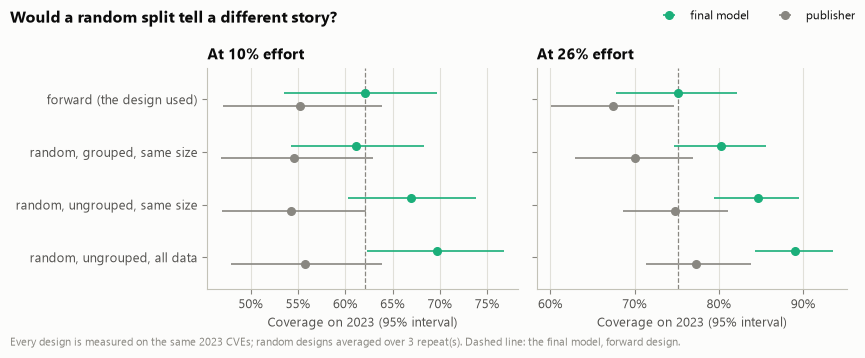

In [24]:
fig, axes = plt.subplots(1, 2, figsize=(8.6, 3.4), sharey=True)
y_pos = np.arange(len(SPLIT_DESIGNS))[::-1]
for ax, e in zip(axes, (PRIMARY_EFFORT, 0.26)):
    t = tag(e)
    for kind, color, shift in (("final model", SET_COLORS[FINAL_MODEL["feature_set"]], 0.12),
                               ("publisher", BASELINE_GREY, -0.12)):
        rows_ = q2_split.loc[[f"{d} · {kind}" for d in SPLIT_DESIGNS]]
        est, low, high = (rows_[f"coverage_{t}{s}"].to_numpy() for s in ("", "_low", "_high"))
        ax.errorbar(est, y_pos + shift, xerr=[est - low, high - est], fmt="o", color=color, ecolor=color,
                    elinewidth=1.2, markersize=5.5, label=kind if e == PRIMARY_EFFORT else None, zorder=3)
    ax.axvline(q2_split.loc[f"{SPLIT_DESIGNS[0]} · final model", f"coverage_{t}"], color=INK_3, linewidth=0.9,
               linestyle="--", zorder=1)
    ax.set_ylim(-0.6, len(SPLIT_DESIGNS) - 0.4)
    ax.xaxis.set_major_formatter(PercentFormatter(1, decimals=0))
    ax.grid(axis="x")
    ax.set_axisbelow(True)
    ax.set_title(f"At {e:.0%} effort", fontsize=10.5)
    ax.set_xlabel("Coverage on 2023 (95% interval)")
axes[0].set_yticks(y_pos, SPLIT_DESIGNS)
fig.suptitle("Would a random split tell a different story?", x=0.01, ha="left", fontweight="bold", fontsize=11.5)
fig.legend(loc="upper right", ncol=2, fontsize=8.5)
fig.tight_layout()
save_figure(fig, "q2_split_check", f"Every design is measured on the same 2023 CVEs; random designs averaged over "
            f"{SPLIT_REPEATS} repeat(s). Dashed line: the final model, forward design.")

**Reading the chart:** each row is a design, each dot a coverage with its 95% interval (aqua: the
final model; grey: the publisher baseline). The dashed line marks the forward result. Dots to its
right show how much more a design would *report* for the same 2023 CVEs.

### Step 14 · What the comparison shows

*(The run of 15 Nov 2026 on the project laptop; a cloud copy with newer library versions gave
identical figures.)*

1. **A plain random split would have overstated our result.** On the same 2023 CVEs it reports
   69.7% coverage at 10% effort instead of 62.1%: **+7.6 points** (95% interval +1.1 to +13.7). At
   26% effort the gap is **+13.8 points** (+7.0 to +20.5): 89.0% instead of 75.2%.
2. **At 10% effort, the gap comes mostly from related CVEs, not from drift.** With publisher-weeks
   kept together, a random split scores about the same as the forward design (61.1% against 62.1%;
   change −0.9 points, −7.6 to +5.6). Letting related CVEs fall on both sides adds **+5.7 points**
   (+2.1 to +9.7), the one clear step at this effort. 123 of the 273 exploited CVEs (45%) share their
   publisher-week with another exploited CVE, and their descriptions are far more alike than those of
   other exploited CVEs (an average similarity of 0.42 against 0.04, on a scale from 0, no shared
   words, to 1, identical wording). The publisher baseline, which ignores the text, gains nothing
   from a random split at 10% effort (+0.6 points, −3.7 to +4.8), though it does at 26% (+9.8 points,
   +3.9 to +16.7).
3. **Drift costs little at the top of the ranking, and perhaps more further down.** At 10% effort,
   learning from 2023-era CVEs did not help (−0.9 points). At 26% effort it added +5.1 points, but the
   interval includes zero (−1.4 to +10.9) and the three repeats ranged from 77.2% to 83.4%: a possible
   cost, not an established one.
4. **More data helps a little.** About 60% more fitting data adds +2.8 points at 10% effort (−0.8 to
   +5.8, not clear) and +4.4 points at 26% (+1.9 to +7.3, clear). This is a real gain, not an
   artefact, and `03_model.ipynb` already takes it: it refits on Nov 2021–2023 before scoring 2024.

**Caveats:**

- **The gap is, if anything, understated.** The final model's settings were chosen on these same 2023
  CVEs with the forward design (`03_model.ipynb`, Step 16), which flatters the forward row. And each
  random design ranks scores pooled from five separately fitted models, which can blur its ranking
  slightly.
- **Grouping by publisher-week is a simple rule.** Related CVEs issued by two publishers (for example
  the vendor and MITRE), or in different weeks, are not kept together. Some leakage may remain in the
  grouped design, so the drift step may include a little of it.
- **One year, 145 exploited CVEs.** The intervals are wide, and the luck of the random parts moved a
  design's coverage by up to 6 points for the final model, and up to 10 for the publisher baseline, at
  26% effort (see the range across repeats). At 10% effort the repeats agree within 4 points.
- **2024 may drift more than 2023.** In 2024, 12.0% of CVEs came from publishers absent in the
  earlier years, against 2.3% in 2023 (`02_descriptive_analysis.ipynb`, Step 13). This check cannot see
  that; the test year will.

**What it means for the project:**

- **Keep the time-based split.** It reports what a team would actually get. For the same model, a plain
  random split would report about 8 points more coverage at 10% effort, and about 14 points more at 26%.
- **Results from studies that split CVEs at random are not directly comparable with ours.** The EPSS
  comparison (Q4) avoids this: both rankings are measured on the same 2024 CVEs.
- **Refitting on every labelled year before scoring 2024** (`03_model.ipynb`, Stage G) is supported by
  the "more data" step.

---

## Stage E · Summary

### Step 15 · Key findings, checks and files

**What we are doing:** saving the headline numbers in `results/q2_split_check_summary.json`, then
listing every check and file and saving the run log.

In [25]:
def at(name, effort):
    "Coverage of one design at one effort, with its interval, as text."
    est, low, high = (q2_split.loc[name, f"coverage_{tag(effort)}{s}"] for s in ("", "_low", "_high"))
    return f"{est:.1%} ({low:.1%}–{high:.1%})"

steps = q2_split_diff.set_index(["ranking", "what_changes", "effort"])
FINDINGS = {"final model": f"{FINAL} {FINAL_MODEL['params']} (frozen by 03_model.ipynb)",
            "clustering": f"{clustered} of {int(y_split.sum())} exploited CVEs share their publisher-week "
                          "with another exploited CVE"}
for e in (PRIMARY_EFFORT, 0.26):
    FINDINGS[f"coverage at {e:.0%} effort"] = "; ".join(f"{d}: {at(f'{d} · final model', e)}" for d in SPLIT_DESIGNS)
    FINDINGS[f"steps at {e:.0%} effort"] = "; ".join(
        f"{label}: {r['change']:+.1%} ({r['low']:+.1%} to {r['high']:+.1%})"
        for label, *_ in SPLIT_STEPS for r in [steps.loc[("final model", label, e)]])
for topic, text in FINDINGS.items():
    print(f"- {topic}: {text}")
save_json(FINDINGS, RESULTS / "q2_split_check_summary.json")

- final model: LR · structured + text {'C': 0.1} (frozen by 03_model.ipynb)
- clustering: 123 of 273 exploited CVEs share their publisher-week with another exploited CVE
- coverage at 10% effort: forward (the design used): 62.1% (53.5%–69.7%); random, grouped, same size: 61.1% (54.3%–68.4%); random, ungrouped, same size: 66.9% (60.3%–73.9%); random, ungrouped, all data: 69.7% (62.3%–76.7%)
- steps at 10% effort: drift: learning from the same years: -0.9% (-7.6% to +5.6%); leakage between related CVEs: +5.7% (+2.1% to +9.7%); more training data: +2.8% (-0.8% to +5.8%); total: plain random split vs forward: +7.6% (+1.1% to +13.7%)
- coverage at 26% effort: forward (the design used): 75.2% (67.8%–82.1%); random, grouped, same size: 80.2% (74.7%–85.6%); random, ungrouped, same size: 84.6% (79.4%–89.5%); random, ungrouped, all data: 89.0% (84.3%–93.5%)
- steps at 26% effort: drift: learning from the same years: +5.1% (-1.4% to +10.9%); leakage between related CVEs: +4.4% (+0.5% to +8.3%); m

**Reading the result:** one line per finding, with 95% intervals in brackets.

**The checks and files:** the last cell lists every check and file and saves the run log.

In [26]:
EXPECTED_CHECKS = ["S0-evaluation-selftest", "S1-inputs-from-03", "S2-model-reproduced", "S3-designs-checked"]
for name in EXPECTED_CHECKS:
    RUN["checks"].setdefault(name, {"verdict": "FAIL", "error": "check never ran"})
RUN["finished"] = now_iso()
LOG_FILE.write_text(json.dumps(RUN, indent=2, default=str), encoding="utf-8")

verdicts = [c["verdict"] for c in RUN["checks"].values()]
print(f"{verdicts.count('PASS')}/{len(verdicts)} checks passed, {verdicts.count('WARN')} to review, "
      f"{verdicts.count('FAIL')} failed")
for name, c in RUN["checks"].items():
    print(f"  {c['verdict']:<5} {name}")
print(f"\n{len(RUN['files'])} files written:")
for path in RUN["files"]:
    print(f"  {path}")

4/4 checks passed, 0 to review, 0 failed
  PASS  S0-evaluation-selftest
  PASS  S1-inputs-from-03
  PASS  S2-model-reproduced
  PASS  S3-designs-checked

5 files written:
  results\q2_split_check.csv
  results\q2_split_check_differences.csv
  results\q2_split_check.json
  figures\q2_split_check.png
  results\q2_split_check_summary.json


**Reading the result:** the target is 4 of 4 checks passed and 5 files written (plus the run log).